# Model: comparación híbrida y experimento solo público

VulnMiner · DavidPilaguano · SEMMA con datos públicos verificables.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'data/dataset.csv').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
df = pd.read_csv(ROOT / 'data/dataset.csv', keep_default_na=False)
df['labels'] = df.labels.map(json.loads)
manifest = json.loads((ROOT / 'data/public_manifest.json').read_text(encoding='utf-8'))
results = json.loads((ROOT / 'output/evaluation/metrics.json').read_text(encoding='utf-8'))
selected = results['candidates'][results['selected']]


El entrenamiento completo se ejecuta con scripts/train.py. Se comparan regresión logística One-vs-Rest (C=0.5/2.0) y Random Forest multisalida (160 árboles, profundidad sin límite/18), semilla 42. El umbral global se selecciona en 0.30/0.40/0.50/0.60 usando F1 macro de validación. Este notebook permite reentrenar explícitamente; por defecto inspecciona el experimento congelado.

In [2]:
REENTRENAR = False
if REENTRENAR:
    from scripts.train import run
    results = run()
    selected = results['candidates'][results['selected']]
display(pd.read_csv(ROOT / 'output/evaluation/comparison.csv'))
assert results['selected'] == max(range(len(results['candidates'])), key=lambda i:(results['candidates'][i]['validation']['f1_macro'], results['candidates'][i]['algorithm']=='LogisticRegression'))
print('Seleccionado por validación:', selected['algorithm'], selected['parameter'], selected['threshold'])

,algorithm,parameter,threshold,validation_f1_macro,test_precision_micro,test_recall_micro,test_f1_micro,test_f1_macro
0,LogisticRegression,0.5,0.6,0.865182,0.681648,0.916877,0.781955,0.740556
1,LogisticRegression,2.0,0.6,0.927528,0.775424,0.921914,0.842348,0.761753
2,RandomForest,NaN,0.4,0.922381,0.936842,0.896725,0.916345,0.877010
3,RandomForest,18.0,0.5,0.869176,0.805755,0.846348,0.825553,0.770240


Seleccionado por validación: LogisticRegression 2.0 0.6


,categoria,puntuacion
0,A01:2025,0.019739
1,A02:2025,0.951704
2,A04:2025,0.012886
3,A05:2025,0.037941
4,A06:2025,0.002784
5,A07:2025,0.005065
6,A08:2025,0.016557
7,API10:2023,0.003090
8,API2:2023,0.007020
9,API7:2023,0.020421


Solo público: particiones {'train': 2832, 'validation': 567, 'test': 567}
Solo público: F1 macro prueba 0.7915920908666344


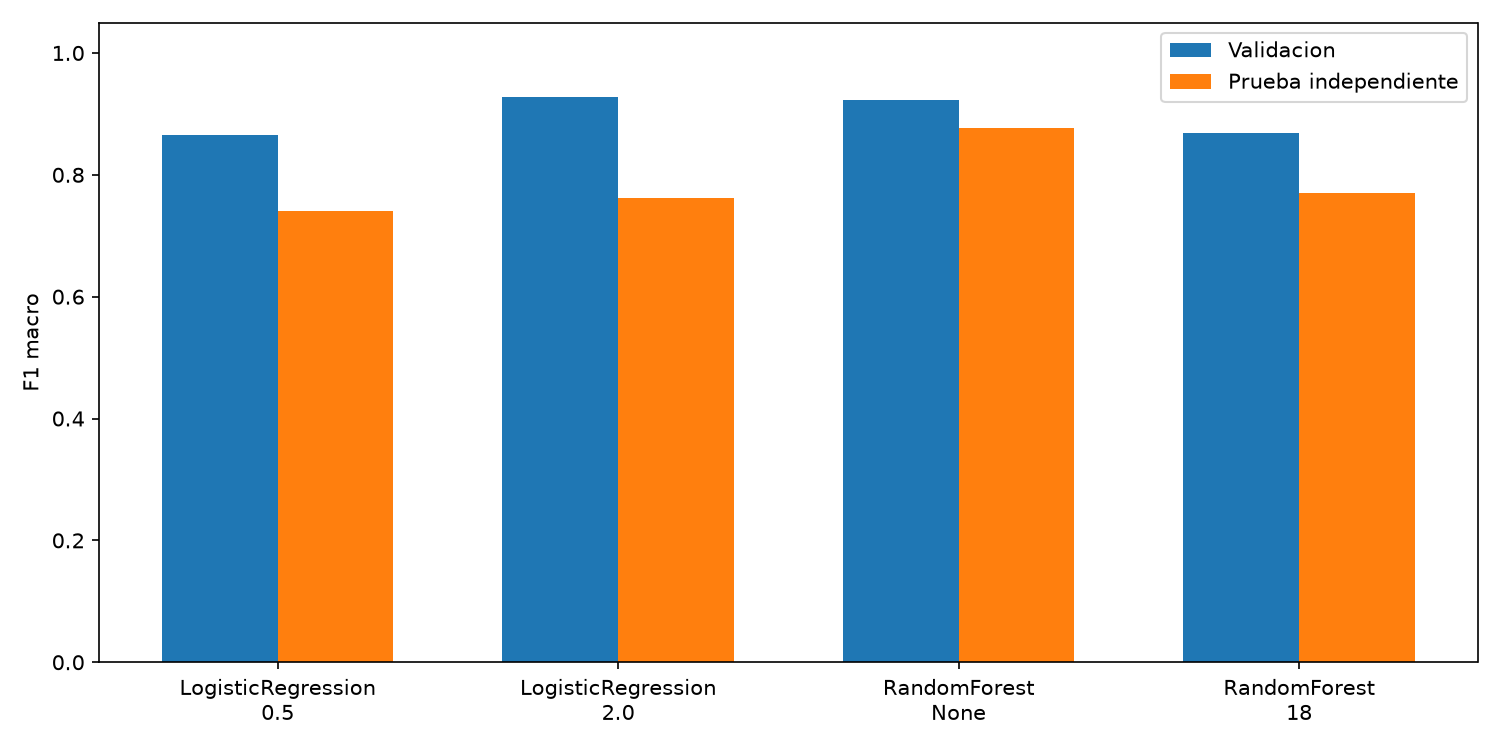

In [3]:
import joblib
bundle = joblib.load(ROOT / 'vulnminer/artifacts/model.joblib')
scores = bundle['estimator'].predict_proba(bundle['features'].transform(['app.run(debug=True)']))[0]
display(pd.DataFrame({'categoria':bundle['classes'],'puntuacion':scores}))
public_result = results['public_only']
print('Solo público: particiones', public_result['records'])
print('Solo público: F1 macro prueba', public_result['test']['f1_macro'])
display(Image(filename=str(ROOT / 'output/evaluation/model_comparison.png')))

El artefacto principal es híbrido porque conserva cobertura API basada en el suplemento. El artefacto public_model.joblib se entrena exclusivamente con los casos descargados y su propio vocabulario, con seis categorías generales y sin etiquetas API. Sus métricas tienen otro universo de categorías y no son directamente comparables con el F1 macro híbrido. No se cambia el ganador por observar un mejor resultado de prueba en otro candidato.